In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\HP\Desktop\RetailIQ")
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORTS_DIR = PROJECT_DIR / "reports"

print("RetailIQ Environment Ready!")
print("Raw dataset folder exists:", RAW_DIR.exists())
print("Processed folder exists:", PROCESSED_DIR.exists())
print("Reports folder exists:", REPORTS_DIR.exists())
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

RetailIQ Environment Ready!
Raw dataset folder exists: True
Processed folder exists: True
Reports folder exists: True
Pandas version: 3.1.0
NumPy version: 2.4.6


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\HP\Desktop\RetailIQ")
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORTS_DIR = PROJECT_DIR / "reports"

print("RetailIQ Environment Ready!")
print("Raw dataset folder exists:", RAW_DIR.exists())
print("Processed folder exists:", PROCESSED_DIR.exists())
print("Reports folder exists:", REPORTS_DIR.exists())
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

RetailIQ Environment Ready!
Raw dataset folder exists: True
Processed folder exists: True
Reports folder exists: True
Pandas version: 3.1.0
NumPy version: 2.4.6


In [3]:
orders = pd.read_csv(RAW_DIR / "olist_orders_dataset.csv")
items = pd.read_csv(RAW_DIR / "olist_order_items_dataset.csv")
payments = pd.read_csv(RAW_DIR / "olist_order_payments_dataset.csv")
products = pd.read_csv(PROCESSED_DIR / "products_cleaned.csv")
customers = pd.read_csv(RAW_DIR / "olist_customers_dataset.csv")

print("ORDERS:", orders.shape)
print("ORDER ITEMS:", items.shape)
print("PAYMENTS:", payments.shape)
print("PRODUCTS:", products.shape)
print("CUSTOMERS:", customers.shape)

display(orders.head())

ORDERS: (99441, 8)
ORDER ITEMS: (112650, 7)
PAYMENTS: (103886, 5)
PRODUCTS: (32951, 10)
CUSTOMERS: (99441, 5)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
# Check data types
print("ORDERS DATA TYPES")
display(orders.dtypes)

# Check missing values
print("\nMISSING VALUES IN ORDERS")
display(orders.isnull().sum())

# Check duplicate order IDs
print("\nDUPLICATE ORDER IDs:", orders["order_id"].duplicated().sum())

# Check order statuses
print("\nORDER STATUS COUNTS")
display(orders["order_status"].value_counts())

# Inspect date columns
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

print("\nDATE COLUMN SAMPLE")
display(orders[date_cols].tail(10))

ORDERS DATA TYPES


order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object


MISSING VALUES IN ORDERS


order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


DUPLICATE ORDER IDs: 0

ORDER STATUS COUNTS


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


DATE COLUMN SAMPLE


,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
99431,2017-10-27 15:21:00,2017-10-27 15:32:49,2017-10-30 15:44:34,2017-11-10 17:57:22,2017-11-22 00:00:00
99432,2017-12-20 09:52:41,2017-12-20 10:09:52,2017-12-20 20:25:25,2018-01-26 15:45:14,2018-01-18 00:00:00
99433,2017-10-04 19:57:37,2017-10-04 20:07:14,2017-10-05 16:52:52,2017-10-20 20:25:45,2017-11-07 00:00:00
99434,2017-01-27 00:30:03,2017-01-27 01:05:25,2017-01-30 11:40:16,2017-02-07 13:15:25,2017-03-17 00:00:00
99435,2017-02-23 09:05:12,2017-02-23 09:15:11,2017-03-01 10:22:52,2017-03-06 11:08:08,2017-03-22 00:00:00
99436,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00
99437,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00
99438,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00
99439,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00
99440,2018-03-08 20:57:30,2018-03-09 11:20:28,2018-03-09 22:11:59,2018-03-16 13:08:30,2018-04-03 00:00:00


In [5]:
# Create a separate analysis copy
orders_analysis = orders.copy()

# Convert date columns to proper datetime format
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    orders_analysis[col] = pd.to_datetime(
        orders_analysis[col],
        errors="coerce"
    )

# Validate conversion
print("DATE CONVERSION COMPLETE")
display(orders_analysis[date_cols].dtypes)

print("\nMissing dates after conversion:")
display(orders_analysis[date_cols].isnull().sum())

print("\nPurchase date range:")
print(
    orders_analysis["order_purchase_timestamp"].min(),
    "to",
    orders_analysis["order_purchase_timestamp"].max()
)

DATE CONVERSION COMPLETE


order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object


Missing dates after conversion:


order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


Purchase date range:
2016-09-04 21:15:19 to 2018-10-17 17:30:18


In [6]:
# Inspect order items
print("ORDER ITEMS COLUMNS")
display(items.dtypes)

print("\nORDER ITEMS SAMPLE")
display(items.head())

print("\nMissing values")
display(items.isnull().sum())

print("\nPrice and freight summary")
display(items[["price", "freight_value"]].describe())

print("\nDuplicate order-item rows")
print(items.duplicated().sum())

print("\nUnique orders in order items:", items["order_id"].nunique())
print("Unique products sold:", items["product_id"].nunique())

ORDER ITEMS COLUMNS


order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object


ORDER ITEMS SAMPLE


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14



Missing values


order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64


Price and freight summary


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000



Duplicate order-item rows
0

Unique orders in order items: 98666
Unique products sold: 32951


In [7]:
# Create a copy for analysis
items_analysis = items.copy()

# Calculate item revenue and freight separately
items_analysis["item_revenue"] = items_analysis["price"]
items_analysis["shipping_revenue"] = items_analysis["freight_value"]

# Aggregate item-level data to order level
order_sales = (
    items_analysis
    .groupby("order_id", as_index=False)
    .agg(
        items_revenue=("item_revenue", "sum"),
        shipping_total=("shipping_revenue", "sum"),
        item_count=("order_item_id", "count")
    )
)

order_sales["order_value_with_shipping"] = (
    order_sales["items_revenue"] + order_sales["shipping_total"]
)

print("Unique orders with items:", len(order_sales))
print("\nSales summary (Brazilian Real - R$):")
display(
    order_sales[
        ["items_revenue", "shipping_total", "order_value_with_shipping"]
    ].describe().round(2)
)

print("\nSample order-level sales:")
display(order_sales.head())

Unique orders with items: 98666

Sales summary (Brazilian Real - R$):


,items_revenue,shipping_total,order_value_with_shipping
count,98666.00,98666.00,98666.00
mean,137.75,22.82,160.58
std,210.65,21.65,220.47
min,0.85,0.00,9.59
25%,45.90,13.85,61.98
50%,86.90,17.17,105.29
75%,149.90,24.04,176.87
max,13440.00,1794.96,13664.08



Sample order-level sales:


,order_id,items_revenue,shipping_total,item_count,order_value_with_shipping
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,1,72.19
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,1,259.83
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,1,216.87
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,1,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,1,218.04


In [8]:
# Join order sales with order status and purchase date
sales_analysis = orders_analysis[
    ["order_id", "order_status", "order_purchase_timestamp"]
].merge(
    order_sales,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Summarize orders by status
status_summary = (
    sales_analysis
    .groupby("order_status", dropna=False)
    .agg(
        total_orders=("order_id", "nunique"),
        orders_with_items=("items_revenue", "count"),
        item_revenue=("items_revenue", "sum"),
        shipping_total=("shipping_total", "sum")
    )
    .reset_index()
)

status_summary["item_revenue"] = status_summary["item_revenue"].round(2)
status_summary["shipping_total"] = status_summary["shipping_total"].round(2)

display(status_summary.sort_values("item_revenue", ascending=False))

# Delivered orders only
delivered = sales_analysis[sales_analysis["order_status"] == "delivered"]

print("\nDelivered orders:", delivered["order_id"].nunique())
print("Delivered orders with items:", delivered["items_revenue"].notna().sum())
print("Delivered item revenue (R$):", round(delivered["items_revenue"].sum(), 2))
print("Delivered shipping total (R$):", round(delivered["shipping_total"].sum(), 2))

,order_status,total_orders,orders_with_items,item_revenue,shipping_total
3,delivered,96478,96478,13221498.11,2198275.64
6,shipped,1107,1106,150727.44,26401.90
1,canceled,625,461,95235.27,10650.45
4,invoiced,314,312,61526.37,7462.38
5,processing,301,301,60439.22,8954.89
7,unavailable,609,6,2007.69,132.80
0,approved,2,2,209.60,31.48
2,created,5,0,0.00,0.00



Delivered orders: 96478
Delivered orders with items: 96478
Delivered item revenue (R$): 13221498.11
Delivered shipping total (R$): 2198275.64


,purchase_month,delivered_orders,item_revenue
11,2017-09,4150,607399.67
12,2017-10,4478,648247.65
13,2017-11,7289,987765.37
14,2017-12,5513,726033.19
15,2018-01,7069,924645.00
16,2018-02,6555,826437.13
17,2018-03,7003,953356.25
18,2018-04,6798,973534.09
19,2018-05,6749,977544.69
20,2018-06,6099,856077.86


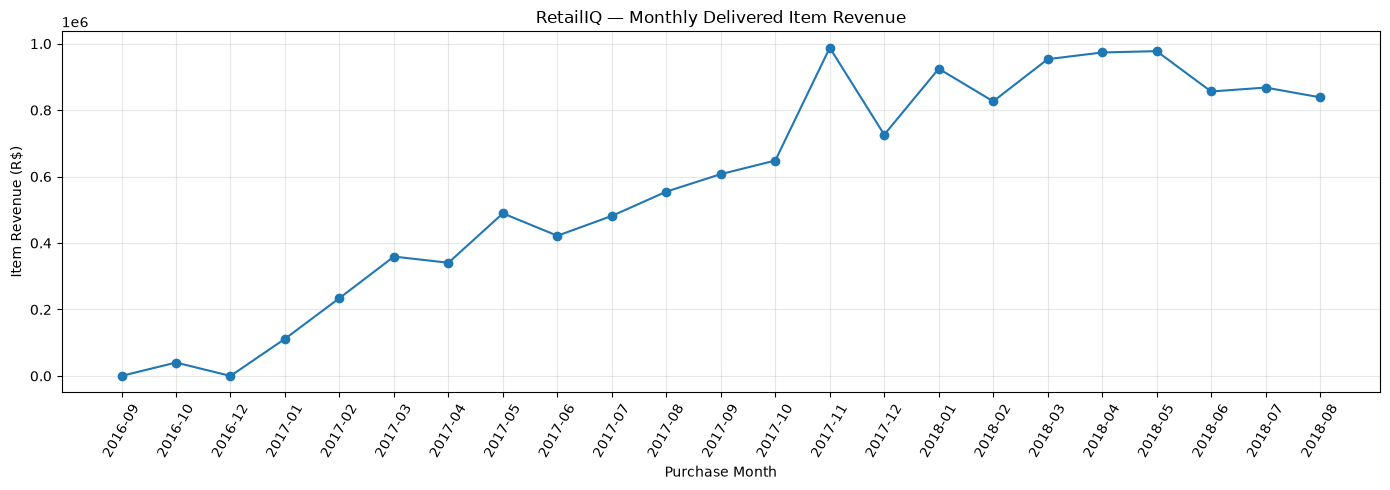

In [9]:
# Keep only delivered orders with valid purchase dates
delivered_monthly = delivered.dropna(
    subset=["order_purchase_timestamp", "items_revenue"]
).copy()

# Create monthly periods
delivered_monthly["purchase_month"] = (
    delivered_monthly["order_purchase_timestamp"]
    .dt.to_period("M")
)

# Aggregate monthly metrics
monthly_sales = (
    delivered_monthly
    .groupby("purchase_month")
    .agg(
        delivered_orders=("order_id", "nunique"),
        item_revenue=("items_revenue", "sum")
    )
    .reset_index()
)

monthly_sales["purchase_month"] = (
    monthly_sales["purchase_month"].astype(str)
)

monthly_sales["item_revenue"] = monthly_sales["item_revenue"].round(2)

display(monthly_sales.tail(12))

# Plot monthly item revenue
plt.figure(figsize=(14, 5))
plt.plot(
    monthly_sales["purchase_month"],
    monthly_sales["item_revenue"],
    marker="o"
)
plt.title("RetailIQ — Monthly Delivered Item Revenue")
plt.xlabel("Purchase Month")
plt.ylabel("Item Revenue (R$)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Top 10 Product Categories by Delivered Item Revenue


,product_category_name_english,units_sold,item_revenue,unique_orders
43,health_beauty,9465,1233131.72,8647
73,watches_gifts,5859,1166176.98,5495
7,bed_bath_table,10953,1023434.76,9272
67,sports_leisure,8431,954852.55,7530
15,computers_accessories,7644,888724.61,6530
39,furniture_decor,8160,711927.69,6307
49,housewares,6795,615628.69,5743
20,cool_stuff,3718,610204.10,3559
5,auto,4140,578966.65,3810
71,toys,4030,471286.48,3804


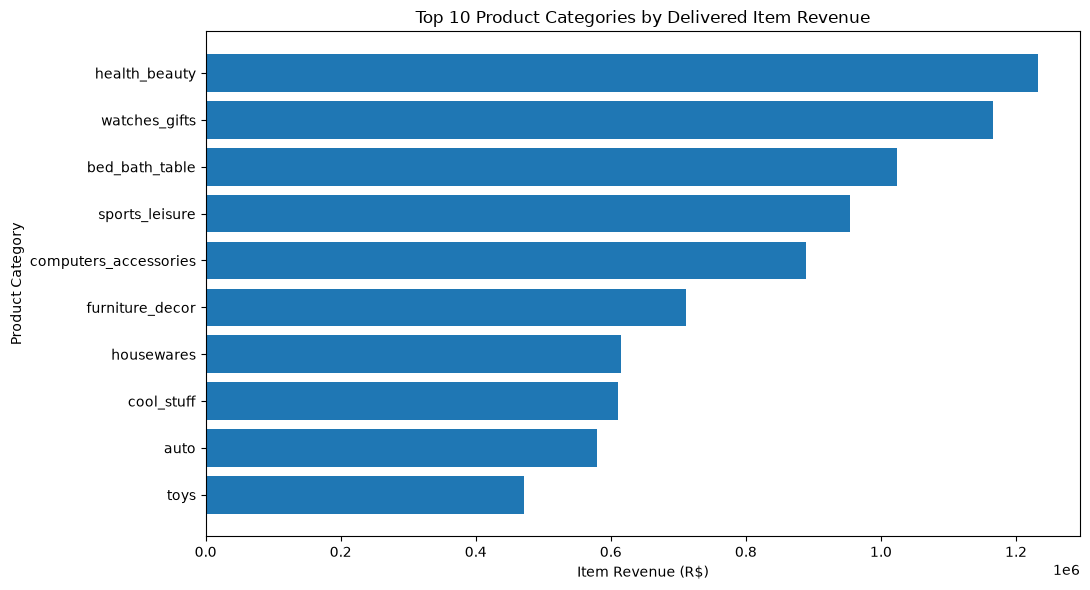

In [10]:
# Join order items with order status and product categories
product_sales = items_analysis.merge(
    orders_analysis[["order_id", "order_status"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

product_sales = product_sales.merge(
    products[["product_id", "product_category_name_english"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Analyze delivered item revenue by category
category_sales = (
    product_sales[product_sales["order_status"] == "delivered"]
    .groupby("product_category_name_english", dropna=False)
    .agg(
        units_sold=("order_item_id", "count"),
        item_revenue=("price", "sum"),
        unique_orders=("order_id", "nunique")
    )
    .reset_index()
    .sort_values("item_revenue", ascending=False)
)

category_sales["item_revenue"] = category_sales["item_revenue"].round(2)

print("Top 10 Product Categories by Delivered Item Revenue")
display(category_sales.head(10))

# Visualize top 10 categories
top_categories = category_sales.head(10).sort_values("item_revenue")

plt.figure(figsize=(11, 6))
plt.barh(
    top_categories["product_category_name_english"],
    top_categories["item_revenue"]
)
plt.title("Top 10 Product Categories by Delivered Item Revenue")
plt.xlabel("Item Revenue (R$)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [11]:
# Analyze delivered orders at customer level
customer_orders = delivered.merge(
    orders_analysis[["order_id", "customer_id"]],
    on="order_id",
    how="left",
    validate="one_to_one"
)

customer_summary = (
    customer_orders
    .groupby("customer_id")
    .agg(
        delivered_orders=("order_id", "nunique"),
        total_item_revenue=("items_revenue", "sum")
    )
    .reset_index()
)

repeat_customers = customer_summary[
    customer_summary["delivered_orders"] > 1
]

print("Unique customers with delivered orders:", len(customer_summary))
print("Customers with multiple delivered orders:", len(repeat_customers))
print(
    "Repeat customer rate (%):",
    round(len(repeat_customers) / len(customer_summary) * 100, 2)
)

print("\nTop 10 customers by delivered item revenue")
display(
    customer_summary
    .sort_values("total_item_revenue", ascending=False)
    .head(10)
    .round(2)
)

Unique customers with delivered orders: 96478
Customers with multiple delivered orders: 0
Repeat customer rate (%): 0.0

Top 10 customers by delivered item revenue


,customer_id,delivered_orders,total_item_revenue
8293,1617b1357756262bfa56ab541c47bc16,1,13440.0
89276,ec5b2ba62e574342386871631fafd3fc,1,7160.0
75240,c6e2731c5b391845f6800c97401a43a9,1,6735.0
92311,f48d464a0baaea338cb25f816991ab1f,1,6729.0
24068,3fd6777bbce08a352fddd04e4a7cc8f6,1,6499.0
2007,05455dfa7cd02f13d132aa7a6a9729c6,1,5934.6
84350,df55c14d1476a9a3467f131269c2477f,1,4799.0
13870,24bbf5fd2f2e1b359ee7de94defc4a15,1,4690.0
23252,3d979689f636322c62418b6346b1c6d2,1,4590.0
77364,cc803a2c412833101651d3f90ca7de24,1,4400.0


In [12]:
# Map orders to the actual unique customer identifier
customer_orders_correct = (
    delivered[["order_id", "items_revenue"]]
    .merge(
        orders_analysis[["order_id", "customer_id"]],
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        customers[["customer_id", "customer_unique_id"]],
        on="customer_id",
        how="left",
        validate="many_to_one"
    )
)

unique_customer_summary = (
    customer_orders_correct
    .groupby("customer_unique_id")
    .agg(
        delivered_orders=("order_id", "nunique"),
        total_item_revenue=("items_revenue", "sum")
    )
    .reset_index()
)

repeat_customers = unique_customer_summary[
    unique_customer_summary["delivered_orders"] > 1
]

print("Unique customers:", unique_customer_summary["customer_unique_id"].nunique())
print("Repeat customers:", len(repeat_customers))
print(
    "Repeat customer rate (%):",
    round(len(repeat_customers) / len(unique_customer_summary) * 100, 2)
)

print("\nDelivered order frequency:")
display(
    unique_customer_summary["delivered_orders"]
    .value_counts()
    .sort_index()
    .head(10)
)

Unique customers: 93358
Repeat customers: 2801
Repeat customer rate (%): 3.0

Delivered order frequency:


delivered_orders
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

In [13]:
# Prepare customer-level RFM data
rfm_source = customer_orders_correct.copy()

rfm_source["order_date"] = rfm_source["order_id"].map(
    orders_analysis.set_index("order_id")["order_purchase_timestamp"]
)

# Use the latest purchase date in the dataset as the reference date
reference_date = rfm_source["order_date"].max() + pd.Timedelta(days=1)

rfm = (
    rfm_source
    .groupby("customer_unique_id")
    .agg(
        last_purchase=("order_date", "max"),
        frequency=("order_id", "nunique"),
        monetary=("items_revenue", "sum")
    )
    .reset_index()
)

rfm["recency_days"] = (
    reference_date - rfm["last_purchase"]
).dt.days

print("RFM reference date:", reference_date.date())
print("Customer count:", len(rfm))
display(rfm[["recency_days", "frequency", "monetary"]].describe().round(2))
display(rfm.head())

RFM reference date: 2018-08-30
Customer count: 93358


,recency_days,frequency,monetary
count,93358.00,93358.00,93358.00
mean,237.94,1.03,141.62
std,152.59,0.21,215.69
min,1.00,1.00,0.85
25%,114.00,1.00,47.65
50%,219.00,1.00,89.73
75%,346.00,1.00,154.74
max,714.00,15.00,13440.00


,customer_unique_id,last_purchase,frequency,monetary,recency_days
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,1,129.90,112
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,1,18.90,115
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,1,69.00,537
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,1,25.99,321
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,1,180.00,288


In [14]:
# Score customers into 1–4 quartiles
# Recency: lower days = better score
rfm["R_score"] = pd.qcut(
    rfm["recency_days"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]
).astype(int)

# Frequency and Monetary: higher values = better score
rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

# Combined RFM score
rfm["RFM_score"] = (
    rfm["R_score"].astype(str)
    + rfm["F_score"].astype(str)
    + rfm["M_score"].astype(str)
)

# Simple business-friendly segmentation
def segment_customer(row):
    if row["R_score"] >= 3 and row["F_score"] >= 3 and row["M_score"] >= 3:
        return "High Value"
    elif row["R_score"] >= 3 and row["F_score"] >= 2:
        return "Loyal / Active"
    elif row["R_score"] >= 3:
        return "Recent Customers"
    elif row["R_score"] <= 2 and row["F_score"] <= 2:
        return "At Risk / Inactive"
    else:
        return "Needs Attention"

rfm["segment"] = rfm.apply(segment_customer, axis=1)

print("Customer Segment Counts")
display(
    rfm["segment"]
    .value_counts()
    .rename_axis("segment")
    .reset_index(name="customers")
)

print("\nSegment Revenue Summary")
display(
    rfm.groupby("segment", observed=True)
    .agg(
        customers=("customer_unique_id", "count"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
        total_monetary=("monetary", "sum")
    )
    .round(2)
    .sort_values("total_monetary", ascending=False)
)

Customer Segment Counts


,segment,customers
0,At Risk / Inactive,23355
1,Needs Attention,23324
2,Loyal / Active,22924
3,High Value,12078
4,Recent Customers,11677



Segment Revenue Summary


,customers,avg_frequency,avg_monetary,total_monetary
segment,,,,
Needs Attention,23324,1.06,142.90,3333093.57
At Risk / Inactive,23355,1.00,138.85,3242922.51
High Value,12078,1.13,240.49,2904629.87
Loyal / Active,22924,1.01,93.33,2139492.35
Recent Customers,11677,1.00,137.14,1601359.81


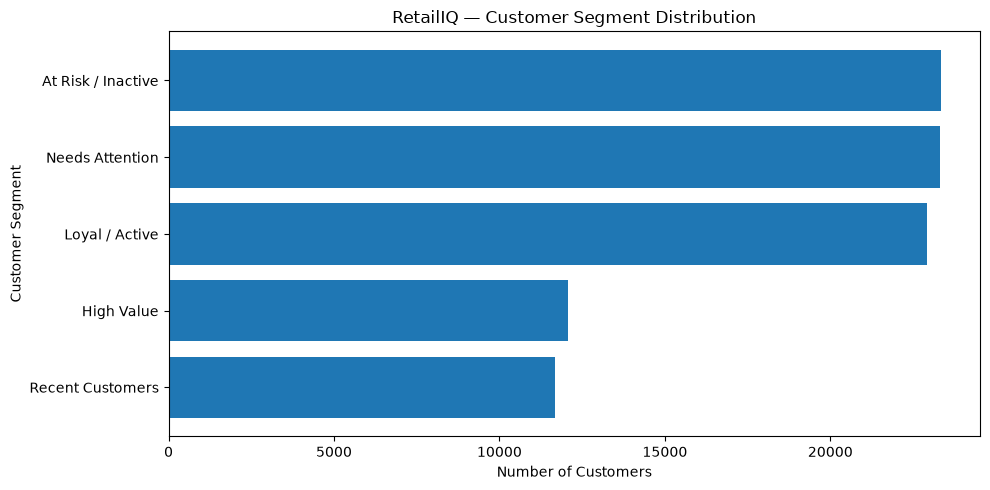

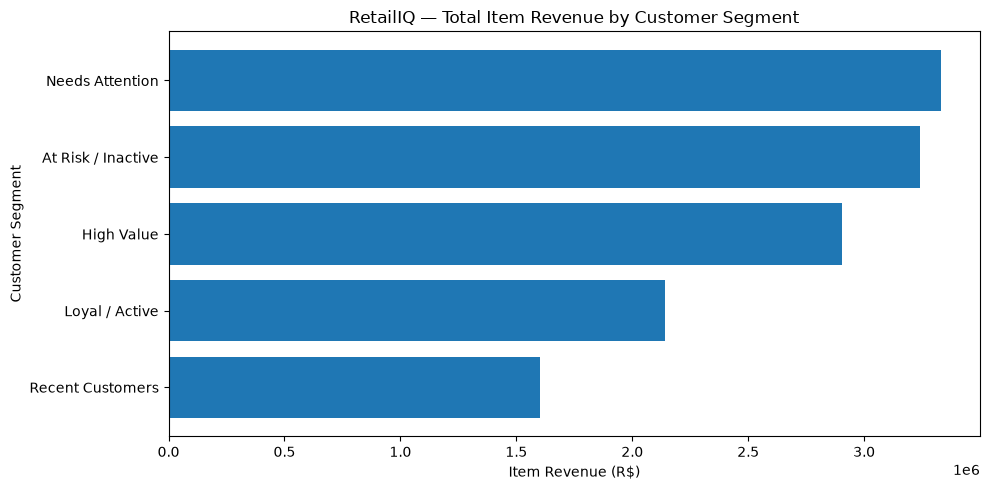

In [15]:
# Visualize customer segment sizes
segment_counts = (
    rfm["segment"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 5))
plt.barh(segment_counts.index, segment_counts.values)
plt.title("RetailIQ — Customer Segment Distribution")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()

# Visualize total item revenue by segment
segment_revenue = (
    rfm.groupby("segment", observed=True)["monetary"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 5))
plt.barh(segment_revenue.index, segment_revenue.values)
plt.title("RetailIQ — Total Item Revenue by Customer Segment")
plt.xlabel("Item Revenue (R$)")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()

In [16]:
# RetailIQ: Export analysis-ready datasets

# 1. Cleaned orders
orders_analysis.to_csv(
    PROCESSED_DIR / "orders_analysis.csv",
    index=False
)

# 2. Order-level sales
sales_analysis.to_csv(
    PROCESSED_DIR / "sales_analysis.csv",
    index=False
)

# 3. Product category performance
category_sales.to_csv(
    REPORTS_DIR / "category_sales_summary.csv",
    index=False
)

# 4. Monthly sales trend
monthly_sales.to_csv(
    REPORTS_DIR / "monthly_sales_summary.csv",
    index=False
)

# 5. Customer RFM segments
rfm.to_csv(
    REPORTS_DIR / "customer_rfm_segments.csv",
    index=False
)

# 6. Repeat customer summary
unique_customer_summary.to_csv(
    REPORTS_DIR / "customer_purchase_summary.csv",
    index=False
)

print("RetailIQ exports completed successfully!")
print("\nProcessed files:")
for file in sorted(PROCESSED_DIR.glob("*.csv")):
    print(file.name)

print("\nReport files:")
for file in sorted(REPORTS_DIR.glob("*.csv")):
    print(file.name)

RetailIQ exports completed successfully!

Processed files:
orders_analysis.csv
orders_cleaned.csv
products_cleaned.csv
sales_analysis.csv

Report files:
category_sales_summary.csv
column_quality_report.csv
customer_purchase_summary.csv
customer_rfm_segments.csv
dataset_summary.csv
monthly_sales_summary.csv


In [17]:
# RetailIQ: Validate exported datasets

required_files = [
    PROCESSED_DIR / "orders_analysis.csv",
    PROCESSED_DIR / "sales_analysis.csv",
    REPORTS_DIR / "category_sales_summary.csv",
    REPORTS_DIR / "monthly_sales_summary.csv",
    REPORTS_DIR / "customer_rfm_segments.csv",
    REPORTS_DIR / "customer_purchase_summary.csv"
]

for file in required_files:
    if file.exists():
        print(f"OK: {file.name} — {file.stat().st_size / 1024:.1f} KB")
    else:
        print(f"MISSING: {file.name}")

print("\nRetailIQ data validation complete!")

OK: orders_analysis.csv — 16222.0 KB
OK: sales_analysis.csv — 8573.7 KB
OK: category_sales_summary.csv — 2.6 KB
OK: monthly_sales_summary.csv — 0.6 KB
OK: customer_rfm_segments.csv — 8354.4 KB
OK: customer_purchase_summary.csv — 3817.5 KB

RetailIQ data validation complete!


In [18]:
# RetailIQ — Executive KPI Summary

total_delivered_orders = delivered["order_id"].nunique()

total_item_revenue = delivered["items_revenue"].sum()

average_order_value = delivered["items_revenue"].mean()

total_customers = rfm["customer_unique_id"].nunique()

repeat_customer_count = (
    unique_customer_summary["delivered_orders"] > 1
).sum()

repeat_customer_rate = (
    repeat_customer_count / total_customers * 100
)

kpi_summary = pd.DataFrame({
    "Metric": [
        "Delivered Orders",
        "Delivered Item Revenue (R$)",
        "Average Item Revenue per Order (R$)",
        "Unique Customers",
        "Repeat Customers",
        "Repeat Customer Rate (%)"
    ],
    "Value": [
        total_delivered_orders,
        round(total_item_revenue, 2),
        round(average_order_value, 2),
        total_customers,
        repeat_customer_count,
        round(repeat_customer_rate, 2)
    ]
})

display(kpi_summary)

,Metric,Value
0,Delivered Orders,96478.00
1,Delivered Item Revenue (R$),13221498.11
2,Average Item Revenue per Order (R$),137.04
3,Unique Customers,93358.00
4,Repeat Customers,2801.00
5,Repeat Customer Rate (%),3.00


In [19]:
# RetailIQ — Revenue vs Shipping Analysis

delivered_sales = sales_analysis[
    sales_analysis["order_status"] == "delivered"
].copy()

revenue_shipping_summary = pd.DataFrame({
    "Metric": [
        "Delivered Orders",
        "Item Revenue (R$)",
        "Shipping Charges (R$)",
        "Total Including Shipping (R$)"
    ],
    "Value": [
        delivered_sales["order_id"].nunique(),
        delivered_sales["items_revenue"].sum(),
        delivered_sales["shipping_total"].sum(),
        (
            delivered_sales["items_revenue"].sum()
            + delivered_sales["shipping_total"].sum()
        )
    ]
})

revenue_shipping_summary["Value"] = (
    revenue_shipping_summary["Value"].round(2)
)

display(revenue_shipping_summary)

,Metric,Value
0,Delivered Orders,96478.00
1,Item Revenue (R$),13221498.11
2,Shipping Charges (R$),2198275.64
3,Total Including Shipping (R$),15419773.75


In [20]:
# RetailIQ — Month-over-Month Sales Growth

monthly_growth = monthly_sales.copy()

monthly_growth["item_revenue"] = pd.to_numeric(
    monthly_growth["item_revenue"],
    errors="coerce"
)

monthly_growth["revenue_change"] = (
    monthly_growth["item_revenue"].diff()
)

monthly_growth["growth_pct"] = (
    monthly_growth["item_revenue"].pct_change() * 100
)

monthly_growth["revenue_change"] = (
    monthly_growth["revenue_change"].round(2)
)

monthly_growth["growth_pct"] = (
    monthly_growth["growth_pct"].round(2)
)

display(
    monthly_growth[
        [
            "purchase_month",
            "delivered_orders",
            "item_revenue",
            "revenue_change",
            "growth_pct"
        ]
    ].tail(12)
)

,purchase_month,delivered_orders,item_revenue,revenue_change,growth_pct
11,2017-09,4150,607399.67,52699.97,9.50
12,2017-10,4478,648247.65,40847.98,6.73
13,2017-11,7289,987765.37,339517.72,52.37
14,2017-12,5513,726033.19,-261732.18,-26.50
15,2018-01,7069,924645.00,198611.81,27.36
16,2018-02,6555,826437.13,-98207.87,-10.62
17,2018-03,7003,953356.25,126919.12,15.36
18,2018-04,6798,973534.09,20177.84,2.12
19,2018-05,6749,977544.69,4010.60,0.41
20,2018-06,6099,856077.86,-121466.83,-12.43


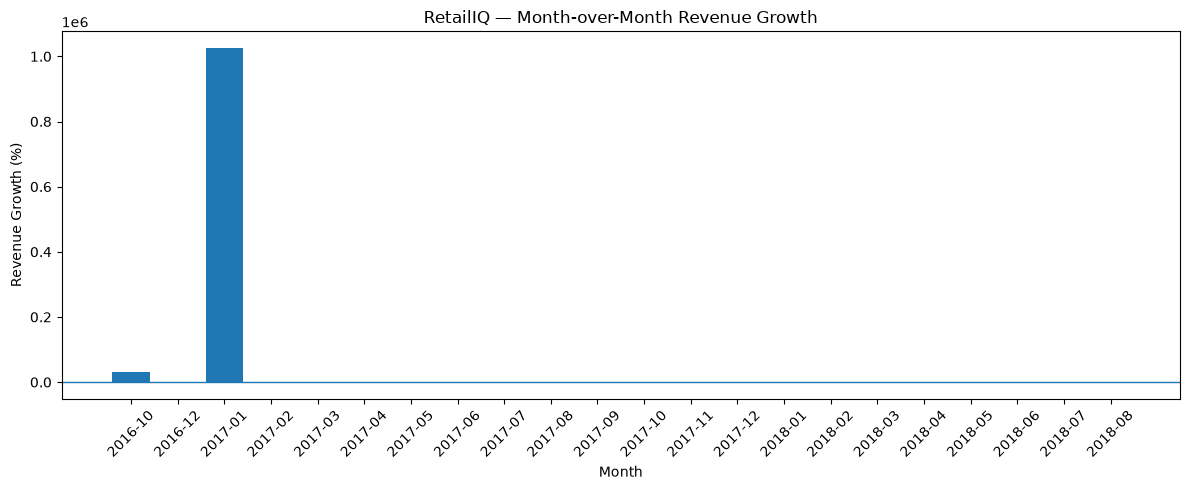

In [21]:
# RetailIQ — Monthly Revenue Growth Chart

growth_chart = monthly_growth.dropna(
    subset=["growth_pct"]
).copy()

plt.figure(figsize=(12, 5))

plt.bar(
    growth_chart["purchase_month"],
    growth_chart["growth_pct"]
)

plt.axhline(y=0, linewidth=1)
plt.title("RetailIQ — Month-over-Month Revenue Growth")
plt.xlabel("Month")
plt.ylabel("Revenue Growth (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
# RetailIQ — Prepare Customer Cohort Data

cohort_data = customer_orders_correct.copy()

cohort_data["order_date"] = cohort_data["order_id"].map(
    orders_analysis.set_index("order_id")["order_purchase_timestamp"]
)

cohort_data = cohort_data.dropna(
    subset=["customer_unique_id", "order_date"]
).copy()

cohort_data["order_month"] = (
    cohort_data["order_date"].dt.to_period("M")
)

cohort_data["cohort_month"] = (
    cohort_data.groupby("customer_unique_id")["order_month"]
    .transform("min")
)

cohort_data["cohort_index"] = (
    (cohort_data["order_month"].dt.year
     - cohort_data["cohort_month"].dt.year) * 12
    + (cohort_data["order_month"].dt.month
       - cohort_data["cohort_month"].dt.month)
    + 1
)

print("Cohort dataset prepared!")
display(cohort_data.head())

Cohort dataset prepared!


,order_id,items_revenue,customer_id,customer_unique_id,order_date,order_month,cohort_month,cohort_index
0,e481f51cbdc54678b7cc49136f2d6af7,29.99,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff,2017-10-02 10:56:33,2017-10,2017-09,2
1,53cdb2fc8bc7dce0b6741e2150273451,118.70,b0830fb4747a6c6d20dea0b8c802d7ef,af07308b275d755c9edb36a90c618231,2018-07-24 20:41:37,2018-07,2018-07,1
2,47770eb9100c2d0c44946d9cf07ec65d,159.90,41ce2a54c0b03bf3443c3d931a367089,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08 08:38:49,2018-08,2018-08,1
3,949d5b44dbf5de918fe9c16f97b45f8a,45.00,f88197465ea7920adcdbec7375364d82,7c142cf63193a1473d2e66489a9ae977,2017-11-18 19:28:06,2017-11,2017-11,1
4,ad21c59c0840e6cb83a9ceb5573f8159,19.90,8ab97904e6daea8866dbdbc4fb7aad2c,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-13 21:18:39,2018-02,2018-02,1


In [23]:
# RetailIQ — Customer Cohort Retention Table

cohort_counts = (
    cohort_data.groupby(["cohort_month", "cohort_index"])
    ["customer_unique_id"]
    .nunique()
    .reset_index()
)

cohort_counts = cohort_counts.rename(
    columns={"customer_unique_id": "customers"}
)

cohort_pivot = cohort_counts.pivot(
    index="cohort_month",
    columns="cohort_index",
    values="customers"
)

cohort_sizes = cohort_pivot.iloc[:, 0]

cohort_retention = cohort_pivot.divide(
    cohort_sizes, axis=0
) * 100

cohort_retention = cohort_retention.round(1)

print("Customer Cohort Retention (%)")
display(cohort_retention)

Customer Cohort Retention (%)


cohort_index,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,20,21
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,100.0,NaN,NaN,NaN,NaN,NaN,0.4,NaN,NaN,0.4,NaN,0.4,NaN,0.4,NaN,0.4,NaN,0.4,0.8,0.8
2016-12,100.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,100.0,0.3,0.3,0.1,0.4,0.1,0.4,0.1,0.1,NaN,0.4,0.1,0.7,0.4,0.1,0.1,0.3,0.4,0.1,NaN
2017-02,100.0,0.2,0.3,0.1,0.4,0.1,0.2,0.2,0.1,0.2,0.1,0.3,0.1,0.2,0.1,0.1,0.1,0.2,NaN,NaN
2017-03,100.0,0.4,0.4,0.4,0.4,0.2,0.2,0.3,0.3,0.1,0.4,0.1,0.2,0.1,0.2,0.2,0.1,0.1,NaN,NaN
2017-04,100.0,0.6,0.2,0.2,0.3,0.3,0.4,0.3,0.3,0.2,0.3,0.1,0.0,0.0,0.1,0.1,0.1,NaN,NaN,NaN
2017-05,100.0,0.5,0.5,0.3,0.3,0.3,0.4,0.1,0.3,0.3,0.3,0.3,0.2,0.0,0.2,0.2,NaN,NaN,NaN,NaN
2017-06,100.0,0.5,0.4,0.4,0.3,0.4,0.4,0.2,0.1,0.2,0.3,0.4,0.2,0.2,0.2,NaN,NaN,NaN,NaN,NaN


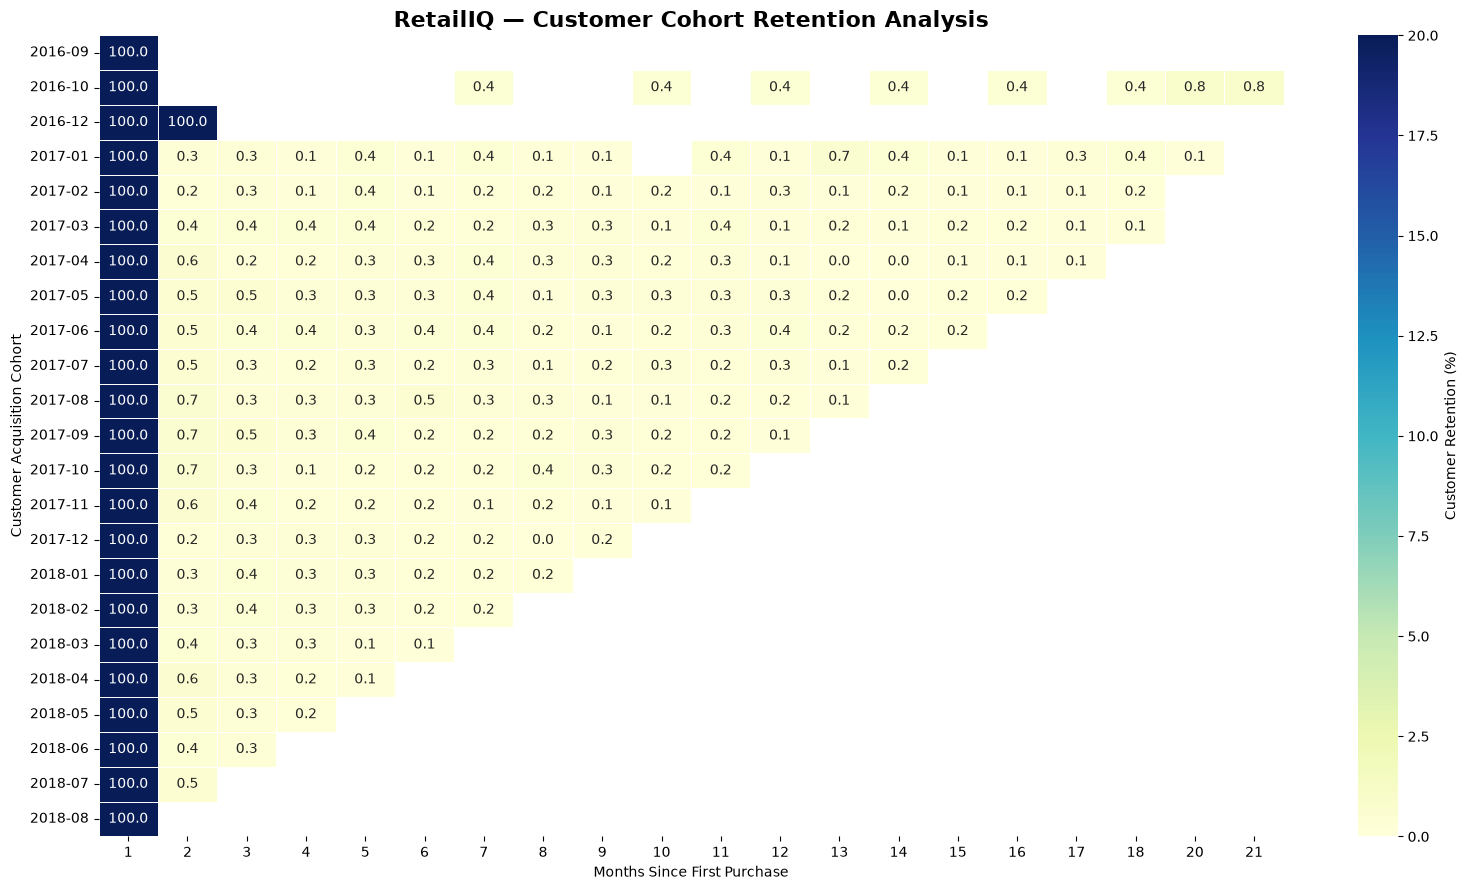

In [24]:
# RetailIQ — Customer Cohort Retention Heatmap

plt.figure(figsize=(16, 9))

sns.heatmap(
    cohort_retention,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=20,
    linewidths=0.4,
    cbar_kws={"label": "Customer Retention (%)"}
)

plt.title(
    "RetailIQ — Customer Cohort Retention Analysis",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Acquisition Cohort")
plt.tight_layout()
plt.show()

In [25]:
# RetailIQ — Business Insights & Recommendations

top_category = category_sales.iloc[0]
top_units_category = category_sales.sort_values(
    "units_sold", ascending=False
).iloc[0]

best_growth_month = monthly_growth.loc[
    monthly_growth["growth_pct"].idxmax()
]
worst_growth_month = monthly_growth.loc[
    monthly_growth["growth_pct"].idxmin()
]

insights = [
    {
        "Area": "Sales",
        "Finding": f"Delivered item revenue was R${total_item_revenue:,.2f}.",
        "Recommendation": "Track revenue trends monthly and compare them with order volume."
    },
    {
        "Area": "Product Category",
        "Finding": (
            f"{top_category['product_category_name_english']} "
            f"generated the highest item revenue: "
            f"R${top_category['item_revenue']:,.2f}."
        ),
        "Recommendation": "Review category demand and stock availability before planning inventory."
    },
    {
        "Area": "Units Sold",
        "Finding": (
            f"{top_units_category['product_category_name_english']} "
            f"had the highest units sold: {int(top_units_category['units_sold']):,}."
        ),
        "Recommendation": "Compare unit demand with revenue to understand product-category performance."
    },
    {
        "Area": "Customer Retention",
        "Finding": f"Repeat customer rate was {repeat_customer_rate:.2f}% in the delivered-order cohort.",
        "Recommendation": "Investigate repeat-purchase barriers and test customer retention campaigns."
    },
    {
        "Area": "Monthly Growth",
        "Finding": (
            f"Highest monthly revenue growth: {best_growth_month['purchase_month']} "
            f"({best_growth_month['growth_pct']:.2f}%)."
        ),
        "Recommendation": "Investigate promotions, product mix and order volume before attributing the growth."
    },
    {
        "Area": "Revenue Decline",
        "Finding": (
            f"Largest monthly revenue decline: {worst_growth_month['purchase_month']} "
            f"({worst_growth_month['growth_pct']:.2f}%)."
        ),
        "Recommendation": "Review category-level sales and order volume to identify possible drivers."
    }
]

business_insights = pd.DataFrame(insights)

display(business_insights)

,Area,Finding,Recommendation
0,Sales,"Delivered item revenue was R$13,221,498.11.",Track revenue trends monthly and compare them ...
1,Product Category,health_beauty generated the highest item reven...,Review category demand and stock availability ...
2,Units Sold,"bed_bath_table had the highest units sold: 10,...",Compare unit demand with revenue to understand...
3,Customer Retention,Repeat customer rate was 3.00% in the delivere...,Investigate repeat-purchase barriers and test ...
4,Monthly Growth,Highest monthly revenue growth: 2017-01 (10255...,"Investigate promotions, product mix and order ..."
5,Revenue Decline,Largest monthly revenue decline: 2016-12 (-99....,Review category-level sales and order volume t...


In [26]:
# RetailIQ — Export Business Insights Report

insights_path = REPORTS_DIR / "business_insights_report.csv"

business_insights.to_csv(
    insights_path,
    index=False,
    encoding="utf-8-sig"
)

print("Business insights report saved successfully!")
print(f"File location: {insights_path}")

Business insights report saved successfully!
File location: C:\Users\HP\Desktop\RetailIQ\reports\business_insights_report.csv


In [27]:
# RetailIQ — Final Reports Validation

required_files = [
    PROCESSED_DIR / "orders_analysis.csv",
    PROCESSED_DIR / "sales_analysis.csv",
    REPORTS_DIR / "category_sales_summary.csv",
    REPORTS_DIR / "monthly_sales_summary.csv",
    REPORTS_DIR / "customer_rfm_segments.csv",
    REPORTS_DIR / "customer_purchase_summary.csv",
    REPORTS_DIR / "business_insights_report.csv"
]

validation_results = []

for file_path in required_files:
    exists = file_path.exists()
    file_size_kb = round(file_path.stat().st_size / 1024, 2) if exists else 0

    validation_results.append({
        "File": file_path.name,
        "Exists": exists,
        "Size (KB)": file_size_kb,
        "Status": "PASS" if exists and file_size_kb > 0 else "CHECK"
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df)

print("\nOverall Status:",
      "PASS" if (validation_df["Status"] == "PASS").all() else "CHECK FILES")

,File,Exists,Size (KB),Status
0,orders_analysis.csv,True,16222.03,PASS
1,sales_analysis.csv,True,8573.73,PASS
2,category_sales_summary.csv,True,2.59,PASS
3,monthly_sales_summary.csv,True,0.56,PASS
4,customer_rfm_segments.csv,True,8354.36,PASS
5,customer_purchase_summary.csv,True,3817.51,PASS
6,business_insights_report.csv,True,0.89,PASS



Overall Status: PASS


In [28]:
# RetailIQ — Dashboard KPI Dataset

dashboard_kpis = pd.DataFrame({
    "KPI": [
        "Delivered Orders",
        "Delivered Item Revenue (R$)",
        "Average Item Revenue per Order (R$)",
        "Unique Customers",
        "Repeat Customers",
        "Repeat Customer Rate (%)",
        "Shipping Charges (R$)",
        "Total Including Shipping (R$)"
    ],
    "Value": [
        total_delivered_orders,
        round(total_item_revenue, 2),
        round(average_order_value, 2),
        total_customers,
        repeat_customer_count,
        round(repeat_customer_rate, 2),
        round(delivered_sales["shipping_total"].sum(), 2),
        round(
            delivered_sales["items_revenue"].sum()
            + delivered_sales["shipping_total"].sum(),
            2
        )
    ]
})

kpi_path = REPORTS_DIR / "dashboard_kpis.csv"

dashboard_kpis.to_csv(
    kpi_path,
    index=False,
    encoding="utf-8-sig"
)

display(dashboard_kpis)

print(f"\nKPI dataset saved: {kpi_path}")

,KPI,Value
0,Delivered Orders,96478.00
1,Delivered Item Revenue (R$),13221498.11
2,Average Item Revenue per Order (R$),137.04
3,Unique Customers,93358.00
4,Repeat Customers,2801.00
5,Repeat Customer Rate (%),3.00
6,Shipping Charges (R$),2198275.64
7,Total Including Shipping (R$),15419773.75



KPI dataset saved: C:\Users\HP\Desktop\RetailIQ\reports\dashboard_kpis.csv


In [29]:
# RetailIQ — Export Dashboard Chart Datasets

# 1. Monthly Sales Chart Data
monthly_chart_data = monthly_sales.copy()

monthly_chart_data.to_csv(
    REPORTS_DIR / "dashboard_monthly_sales.csv",
    index=False,
    encoding="utf-8-sig"
)

# 2. Product Category Chart Data — Top 10
category_chart_data = (
    category_sales
    .sort_values("item_revenue", ascending=False)
    .head(10)
    .copy()
)

category_chart_data.to_csv(
    REPORTS_DIR / "dashboard_top_categories.csv",
    index=False,
    encoding="utf-8-sig"
)

# 3. Customer Segment Chart Data
segment_chart_data = (
    rfm.groupby("segment")
    .agg(
        customers=("customer_unique_id", "nunique"),
        total_item_revenue=("monetary", "sum")
    )
    .reset_index()
    .sort_values("customers", ascending=False)
)

segment_chart_data.to_csv(
    REPORTS_DIR / "dashboard_customer_segments.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dashboard chart datasets exported successfully!")

display(monthly_chart_data.tail())
display(category_chart_data)
display(segment_chart_data)

Dashboard chart datasets exported successfully!


,purchase_month,delivered_orders,item_revenue
18,2018-04,6798,973534.09
19,2018-05,6749,977544.69
20,2018-06,6099,856077.86
21,2018-07,6159,867953.46
22,2018-08,6351,838576.64


,product_category_name_english,units_sold,item_revenue,unique_orders
43,health_beauty,9465,1233131.72,8647
73,watches_gifts,5859,1166176.98,5495
7,bed_bath_table,10953,1023434.76,9272
67,sports_leisure,8431,954852.55,7530
15,computers_accessories,7644,888724.61,6530
39,furniture_decor,8160,711927.69,6307
49,housewares,6795,615628.69,5743
20,cool_stuff,3718,610204.10,3559
5,auto,4140,578966.65,3810
71,toys,4030,471286.48,3804


,segment,customers,total_item_revenue
0,At Risk / Inactive,23355,3242922.51
3,Needs Attention,23324,3333093.57
2,Loyal / Active,22924,2139492.35
1,High Value,12078,2904629.87
4,Recent Customers,11677,1601359.81


In [1]:
from pathlib import Path

PROJECT = Path(r"C:\Users\HP\Desktop\RetailIQ")

print("RETAILIQ - EXPORTED CSV FILES")
print("=" * 50)

csv_files = list(PROJECT.rglob("*.csv"))

for file in csv_files:
    print(f"{file.relative_to(PROJECT)} | {file.stat().st_size:,} bytes")

print("=" * 50)
print("Total CSV files:", len(csv_files))

RETAILIQ - EXPORTED CSV FILES
data\processed\orders_analysis.csv | 16,611,357 bytes
data\processed\orders_cleaned.csv | 17,506,326 bytes
data\processed\products_cleaned.csv | 3,284,816 bytes
data\processed\sales_analysis.csv | 8,779,503 bytes
data\raw\olist_customers_dataset.csv | 9,033,957 bytes
data\raw\olist_geolocation_dataset.csv | 61,273,883 bytes
data\raw\olist_orders_dataset.csv | 17,654,914 bytes
data\raw\olist_order_items_dataset.csv | 15,438,671 bytes
data\raw\olist_order_payments_dataset.csv | 5,777,138 bytes
data\raw\olist_order_reviews_dataset.csv | 14,451,670 bytes
data\raw\olist_products_dataset.csv | 2,379,446 bytes
data\raw\olist_sellers_dataset.csv | 174,703 bytes
data\raw\product_category_name_translation.csv | 2,613 bytes
reports\business_insights_report.csv | 910 bytes
reports\category_sales_summary.csv | 2,657 bytes
reports\column_quality_report.csv | 3,143 bytes
reports\customer_purchase_summary.csv | 3,909,130 bytes
reports\customer_rfm_segments.csv | 8,554,869

In [2]:
import pandas as pd
from pathlib import Path

REPORTS = Path(r"C:\Users\HP\Desktop\RetailIQ\reports")

files = [
    "dashboard_kpis.csv",
    "dashboard_monthly_sales.csv",
    "dashboard_top_categories.csv",
    "dashboard_customer_segments.csv"
]

for filename in files:
    path = REPORTS / filename
    df = pd.read_csv(path)

    print("\n" + "=" * 60)
    print("FILE:", filename)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nPreview:")
    display(df.head(5))


FILE: dashboard_kpis.csv
Shape: (8, 2)
Columns: ['KPI', 'Value']

Preview:


,KPI,Value
0,Delivered Orders,96478.00
1,Delivered Item Revenue (R$),13221498.11
2,Average Item Revenue per Order (R$),137.04
3,Unique Customers,93358.00
4,Repeat Customers,2801.00



FILE: dashboard_monthly_sales.csv
Shape: (23, 3)
Columns: ['purchase_month', 'delivered_orders', 'item_revenue']

Preview:


,purchase_month,delivered_orders,item_revenue
0,2016-09,1,134.97
1,2016-10,265,40325.11
2,2016-12,1,10.90
3,2017-01,750,111798.36
4,2017-02,1653,234223.40



FILE: dashboard_top_categories.csv
Shape: (10, 4)
Columns: ['product_category_name_english', 'units_sold', 'item_revenue', 'unique_orders']

Preview:


,product_category_name_english,units_sold,item_revenue,unique_orders
0,health_beauty,9465,1233131.72,8647
1,watches_gifts,5859,1166176.98,5495
2,bed_bath_table,10953,1023434.76,9272
3,sports_leisure,8431,954852.55,7530
4,computers_accessories,7644,888724.61,6530



FILE: dashboard_customer_segments.csv
Shape: (5, 3)
Columns: ['segment', 'customers', 'total_item_revenue']

Preview:


,segment,customers,total_item_revenue
0,At Risk / Inactive,23355,3242922.51
1,Needs Attention,23324,3333093.57
2,Loyal / Active,22924,2139492.35
3,High Value,12078,2904629.87
4,Recent Customers,11677,1601359.81


In [3]:
from pathlib import Path

PROJECT = Path(r"C:\Users\HP\Desktop\RetailIQ")

print("app.py exists:", (PROJECT / "app.py").exists())
print("dashboard folder exists:", (PROJECT / "dashboard").exists())

print("\nProject root files:")
for item in PROJECT.iterdir():
    print(item.name)

app.py exists: True
dashboard folder exists: False

Project root files:
.ipynb_checkpoints
app.py
data
reports
RetailIQAnalysis.ipynb
scripts
Untitled.ipynb
Untitled1.ipynb


In [4]:
from pathlib import Path

app_path = Path(r"C:\Users\HP\Desktop\RetailIQ\app.py")

content = app_path.read_text(encoding="utf-8")

print("APP.PY LENGTH:", len(content))
print("=" * 60)
print(content[:10000])

APP.PY LENGTH: 6351

from pathlib import Path

import pandas as pd
import plotly.express as px
import streamlit as st

# --------------------------------------------------
# RetailIQ - Retail Intelligence Dashboard
# --------------------------------------------------

PROJECT_DIR = Path(__file__).resolve().parent
REPORTS_DIR = PROJECT_DIR / "reports"

st.set_page_config(
    page_title="RetailIQ | Retail Intelligence",
    page_icon="📊",
    layout="wide",
)

st.title("RetailIQ")
st.subheader("Retail Intelligence & Customer Analytics")
st.caption("E-commerce analytics | Olist dataset | Local dashboard")

# Load exported analysis data
@st.cache_data
def load_data():
    monthly = pd.read_csv(REPORTS_DIR / "monthly_sales_summary.csv")
    categories = pd.read_csv(REPORTS_DIR / "category_sales_summary.csv")
    rfm = pd.read_csv(REPORTS_DIR / "customer_rfm_segments.csv")
    sales = pd.read_csv(PROJECT_DIR / "data" / "processed" / "sales_analysis.csv")
    return monthly, categories, rfm,

In [5]:
from pathlib import Path
from datetime import datetime
import shutil

PROJECT = Path(r"C:\Users\HP\Desktop\RetailIQ")

source = PROJECT / "app.py"
backup = PROJECT / "app_backup_before_upgrade.py"

if backup.exists():
    print("Backup already exists. No overwrite performed.")
else:
    shutil.copy2(source, backup)
    print("Backup created:", backup.name)

print("Original app.py preserved:", source.exists())

Backup created: app_backup_before_upgrade.py
Original app.py preserved: True


In [6]:
import streamlit as st
import plotly
import pandas as pd

print("Streamlit Version:", st.__version__)
print("Plotly Version:", plotly.__version__)
print("Pandas Version:", pd.__version__)

Streamlit Version: 1.66.1
Plotly Version: 7.1.0
Pandas Version: 3.1.0


In [7]:
from pathlib import Path

PROJECT = Path(r"C:\Users\HP\Desktop\RetailIQ")
NEW_APP = PROJECT / "dashboard_app.py"

print("New dashboard file exists:", NEW_APP.exists())
print("Original app preserved:", (PROJECT / "app.py").exists())
print("Backup preserved:", (PROJECT / "app_backup_before_upgrade.py").exists())

New dashboard file exists: False
Original app preserved: True
Backup preserved: True


In [8]:
from pathlib import Path

PROJECT = Path(r"C:\Users\HP\Desktop\RetailIQ")
APP_FILE = PROJECT / "dashboard_app.py"

dashboard_code = r'''
from pathlib import Path
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st

PROJECT = Path(__file__).resolve().parent
REPORTS = PROJECT / "reports"

st.set_page_config(
    page_title="RetailIQ | Business Intelligence",
    page_icon="📊",
    layout="wide"
)

st.title("📊 RetailIQ")
st.subheader("E-Commerce Business Intelligence Dashboard")
st.caption("Industrial-level Retail Analytics | Olist Dataset")

@st.cache_data
def load_data():
    return {
        "kpis": pd.read_csv(REPORTS / "dashboard_kpis.csv"),
        "monthly": pd.read_csv(REPORTS / "dashboard_monthly_sales.csv"),
        "categories": pd.read_csv(REPORTS / "dashboard_top_categories.csv"),
        "segments": pd.read_csv(REPORTS / "dashboard_customer_segments.csv")
    }

try:
    data = load_data()
except Exception as error:
    st.error(f"Data loading failed: {error}")
    st.stop()

kpis = data["kpis"]
monthly = data["monthly"]
categories = data["categories"]
segments = data["segments"]

for frame in [monthly, categories, segments]:
    for col in frame.select_dtypes(include="object").columns:
        frame[col] = frame[col].fillna("Unknown")

st.sidebar.title("Dashboard Navigation")
st.sidebar.caption("RetailIQ Analytics Platform")

page = st.sidebar.radio(
    "Select Module",
    ["Executive Overview", "Sales Analytics",
     "Category Analytics", "Customer Intelligence"]
)

st.sidebar.divider()
st.sidebar.caption("Data Source: Olist Brazilian E-Commerce")

def kpi_value(name):
    result = kpis.loc[kpis["KPI"] == name, "Value"]
    return float(result.iloc[0]) if not result.empty else 0

if page == "Executive Overview":
    st.header("Executive Business Overview")

    metrics = [
        ("Delivered Orders", f"{kpi_value('Delivered Orders'):,.0f}"),
        ("Item Revenue", f"R$ {kpi_value('Delivered Item Revenue (R$)'):,.2f}"),
        ("Avg Revenue / Order", f"R$ {kpi_value('Average Item Revenue per Order (R$)'):,.2f}"),
        ("Unique Customers", f"{kpi_value('Unique Customers'):,.0f}")
    ]

    cols = st.columns(4)
    for col, (label, value) in zip(cols, metrics):
        col.metric(label, value)

    st.divider()
    st.subheader("Monthly Revenue Performance")

    fig = px.area(
        monthly,
        x="purchase_month",
        y="item_revenue",
        markers=True,
        title="Monthly Delivered Item Revenue",
        labels={
            "purchase_month": "Month",
            "item_revenue": "Revenue (R$)"
        }
    )
    st.plotly_chart(fig, use_container_width=True)

    left, right = st.columns(2)

    with left:
        st.subheader("Top Product Categories")
        top = categories.nlargest(5, "item_revenue")
        fig = px.bar(
            top,
            x="item_revenue",
            y="product_category_name_english",
            orientation="h",
            title="Top 5 Categories"
        )
        fig.update_layout(yaxis={"categoryorder": "total ascending"})
        st.plotly_chart(fig, use_container_width=True)

    with right:
        st.subheader("Customer Segments")
        fig = px.pie(
            segments,
            names="segment",
            values="customers",
            hole=0.55,
            title="Customer Distribution"
        )
        st.plotly_chart(fig, use_container_width=True)

elif page == "Sales Analytics":
    st.header("Sales Performance Analytics")

    monthly["item_revenue"] = pd.to_numeric(monthly["item_revenue"], errors="coerce")
    monthly["delivered_orders"] = pd.to_numeric(monthly["delivered_orders"], errors="coerce")

    col1, col2 = st.columns(2)

    with col1:
        fig = px.line(
            monthly,
            x="purchase_month",
            y="item_revenue",
            markers=True,
            title="Monthly Revenue Trend"
        )
        st.plotly_chart(fig, use_container_width=True)

    with col2:
        fig = px.bar(
            monthly,
            x="purchase_month",
            y="delivered_orders",
            title="Monthly Delivered Orders"
        )
        st.plotly_chart(fig, use_container_width=True)

    st.dataframe(monthly, use_container_width=True, hide_index=True)

elif page == "Category Analytics":
    st.header("Product Category Intelligence")

    categories["item_revenue"] = pd.to_numeric(categories["item_revenue"], errors="coerce")
    categories["units_sold"] = pd.to_numeric(categories["units_sold"], errors="coerce")

    top_n = st.slider("Select Top Categories", 5, 10, 10)
    top = categories.nlargest(top_n, "item_revenue")

    fig = px.bar(
        top.sort_values("item_revenue"),
        x="item_revenue",
        y="product_category_name_english",
        orientation="h",
        color="units_sold",
        title=f"Top {top_n} Categories by Revenue",
        hover_data=["unique_orders"]
    )
    st.plotly_chart(fig, use_container_width=True)
    st.dataframe(top, use_container_width=True, hide_index=True)

elif page == "Customer Intelligence":
    st.header("Customer Segmentation Intelligence")

    segments["customers"] = pd.to_numeric(segments["customers"], errors="coerce")
    segments["total_item_revenue"] = pd.to_numeric(
        segments["total_item_revenue"], errors="coerce"
    )

    left, right = st.columns(2)

    with left:
        fig = px.pie(
            segments,
            names="segment",
            values="customers",
            hole=0.5,
            title="Customer Segment Distribution"
        )
        st.plotly_chart(fig, use_container_width=True)

    with right:
        fig = px.bar(
            segments,
            x="segment",
            y="total_item_revenue",
            title="Revenue by Customer Segment"
        )
        st.plotly_chart(fig, use_container_width=True)

    st.dataframe(segments, use_container_width=True, hide_index=True)

st.divider()
st.caption("RetailIQ | Portfolio Project | Built with Python, Streamlit & Plotly")
'''

if APP_FILE.exists():
    raise FileExistsError("dashboard_app.py already exists. No overwrite performed.")

APP_FILE.write_text(dashboard_code, encoding="utf-8")

print("Dashboard application created successfully!")
print("File:", APP_FILE)
print("Size:", APP_FILE.stat().st_size, "bytes")

Dashboard application created successfully!
File: C:\Users\HP\Desktop\RetailIQ\dashboard_app.py
Size: 6131 bytes
